In [2]:
import numpy as np
import pandas as pd

def price_bond_simple(face_value: float, coupon_rate: float,
                        yield_rate: float, periods: int) -> float:
    """
    Calcule le prix dirty d'une obligation à coupon fixe.

    Paramètres:
    -----------
    face_value : float
        La valeur nominale de l'obligation (généralement 100)
    coupon_rate : float
        Le taux de coupon annuel en décimal(ex: 0.04 pour 4%)
    yield_rate : float
        Le taux de rendement annuel en décimal (ex: 0.05 pour 5%)
    periods : int
        Le nombre de périodes semestriellesrestantes jusqu'à l'échéance

    Retourne:
    --------
    float
        Le prix dirty de l'obligation pour 100 de nomianal
    """
    coupon = face_value * coupon_rate / 2 #coupon semestriel
    y = yield_rate / 2 #taux de rendement semestriel

    #Valeur actuelle des coupons (annuité)
    pv_coupon = coupon * (1 - (1 + y) ** (-periods)) / y

    #Valeur actuelle du principal
    pv_principal = face_value / (1 + y) ** periods

    #Prix dirty
    dirty_price = pv_coupon + pv_principal

    return dirty_price

In [3]:
#Exemple : obligation 4% de coupon, échéance 10 ans, rendement 4%
dirty_price = price_bond_simple(face_value=100, 
                                coupon_rate=0.04, 
                                yield_rate=0.05, 
                                periods=20
)

print(f'Prix: {dirty_price: .4f}')
#Quand coupon = yield, le prix est exactement 100 (at parité)


Prix:  92.2054


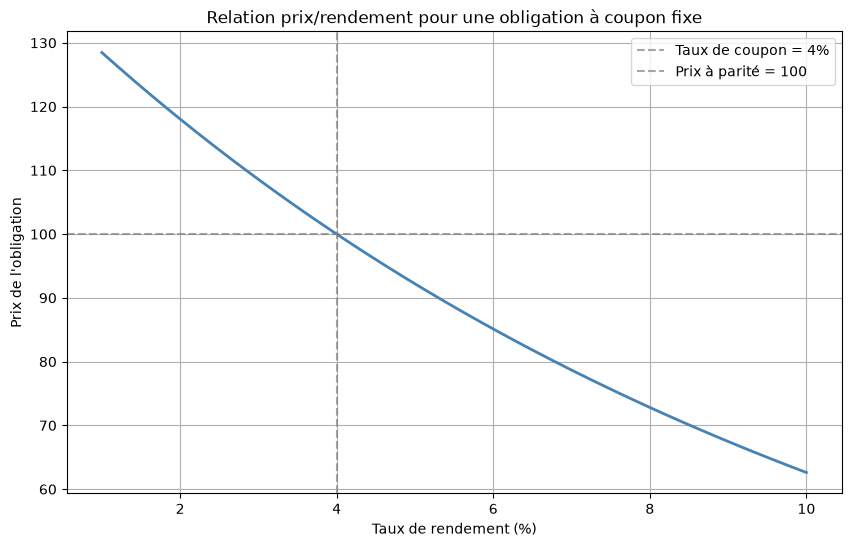

In [5]:
yields = np.linspace(0.01, 0.10, 100) #taux de rendement de 1% à 10%
prices = [price_bond_simple(face_value=100, coupon_rate=0.04, yield_rate=y, periods=20) for y in yields]

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(yields*100, prices, color='steelblue', linewidth=2)
plt.axvline(x=4, color='gray', linestyle='--', alpha=0.7, label='Taux de coupon = 4%')
plt.axhline(y=100, color='gray', linestyle='--', alpha=0.7, label='Prix à parité = 100')
plt.xlabel('Taux de rendement (%)')
plt.ylabel('Prix de l\'obligation')
plt.title('Relation prix/rendement pour une obligation à coupon fixe')
plt.legend()
plt.grid(True)
plt.show()

Calcul des intérêts courus

In [8]:
def accrued_interest(face_value: float, coupon_rate: float,
                     days_since_last_coupon: int, days_in_period: int = 182) -> float:
    """
    Calcule les intérêts courus pour une obligation à coupon fixe.

    Paramètres:
    -----------
    face_value : float
        La valeur nominale de l'obligation (généralement 100)
    coupon_rate : float
        Le taux de coupon annuel en décimal (ex: 0.04 pour 4%)
    days_since_last_coupon : int
        Le nombre de jours écoulés depuis le dernier paiement de coupon
    days_in_period : int
        Le nombre total de jours dans la période de coupon (environ 182 jours pour semestriel)

    Retourne:
    --------
    float
        Les intérêts courus pour l'obligation de nominal 100
    """
    coupon_semestriel = face_value * coupon_rate / 2 #coupon semestriel
    #Convention de comptage des intérêts courus : 30/360 ou actual/actual. Ici, on utilise actual/actual pour simplifier.
    accrued_interest = coupon_semestriel * (days_since_last_coupon / days_in_period)
    
    return accrued_interest

In [9]:
#Exemple : 90 jours depuis le dernier coupon pour une obligation 4% de coupon, échéance 10 ans
accrued = accrued_interest(face_value=100, coupon_rate=0.04, days_since_last_coupon=90)
print(f'Intérêts courus: {accrued: .4f}')

#Clean price = dirty price - accrued interest
dirty_price = price_bond_simple(face_value=100, coupon_rate=0.04, yield_rate=0.05, periods=20)
clean_price = dirty_price - accrued
print(f'Prix dirty: {dirty_price: .4f}')
print(f'Prix clean: {clean_price: .4f}')

Intérêts courus:  0.9890
Prix dirty:  92.2054
Prix clean:  91.2164


Calcul du DV01

In [10]:
def DV01(face_value: float, coupon_rate: float,
            yield_rate: float, periods: int) -> float:
    """
    Calcule le DV01 (Delta Value per 0.01) par choc numérique de 1 basis point.

    Paramètres:
    -----------
    face_value : float
        La valeur nominale de l'obligation
    coupon_rate : float
        Le taux de coupon annuel en décimal
    yield_rate : float
        Le taux de rendement en décimal
    periods : int
        Le nombre de périodes semestrielles restantes jusqu'à l'échéance

    Retourne:
    --------
    float
        Le DV01 de l'obligation
    """

    bp = 0.0001  # 1 basis point = 0.01%    
    # Calcul du prix de l'obligation pour un changement de yield de 0.01 (1 basis point)
    price_up = price_bond_simple(face_value, coupon_rate, yield_rate + bp, periods)
    price_down = price_bond_simple(face_value, coupon_rate, yield_rate - bp, periods)

    # DV01 est la demi-différence des prix
    dv01 = (price_down - price_up) / 2

    return dv01

In [11]:
#Exemple
dv01_value = DV01(face_value=100, coupon_rate=0.04, yield_rate=0.05, periods=20)
print(f'DV01: {dv01_value: .4f}')
print(f'Interpretation : si les taux montent de 1bp, le prix baisse de {dv01_value: .4f} pour une obligation de nominal 100')

DV01:  0.0743
Interpretation : si les taux montent de 1bp, le prix baisse de  0.0743 pour une obligation de nominal 100
